# Excel t-SNE scatter chart

This notebook reads one long-format Excel worksheet and places every sample on one scatter chart. Each row is one point; label groups may contain different numbers of samples.

You choose the label, x-coordinate, and y-coordinate columns. The x/y axis titles are entered separately, so the same workflow can be used for t-SNE, UMAP, or other embeddings.

In [1]:
# Run this only if the required packages are not installed.
# %pip install -r ../requirements.txt

In [2]:
from pathlib import Path
import importlib.util
import sys

# Open this notebook from the scatter-chart-demo folder.
NOTEBOOK_DIR = Path.cwd()
SCRIPT_PATH = NOTEBOOK_DIR / "scatter-chart.py"
if not SCRIPT_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {SCRIPT_PATH}. Open this notebook from the scatter-chart-demo folder."
    )

if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

MODULE_SPEC = importlib.util.spec_from_file_location("scatter_chart", SCRIPT_PATH)
if MODULE_SPEC is None or MODULE_SPEC.loader is None:
    raise ImportError(f"Could not load {SCRIPT_PATH}.")
scatter_chart = importlib.util.module_from_spec(MODULE_SPEC)
MODULE_SPEC.loader.exec_module(scatter_chart)
main = scatter_chart.main

PNG saved to: tsne_demo_data_tsne_scatter.png


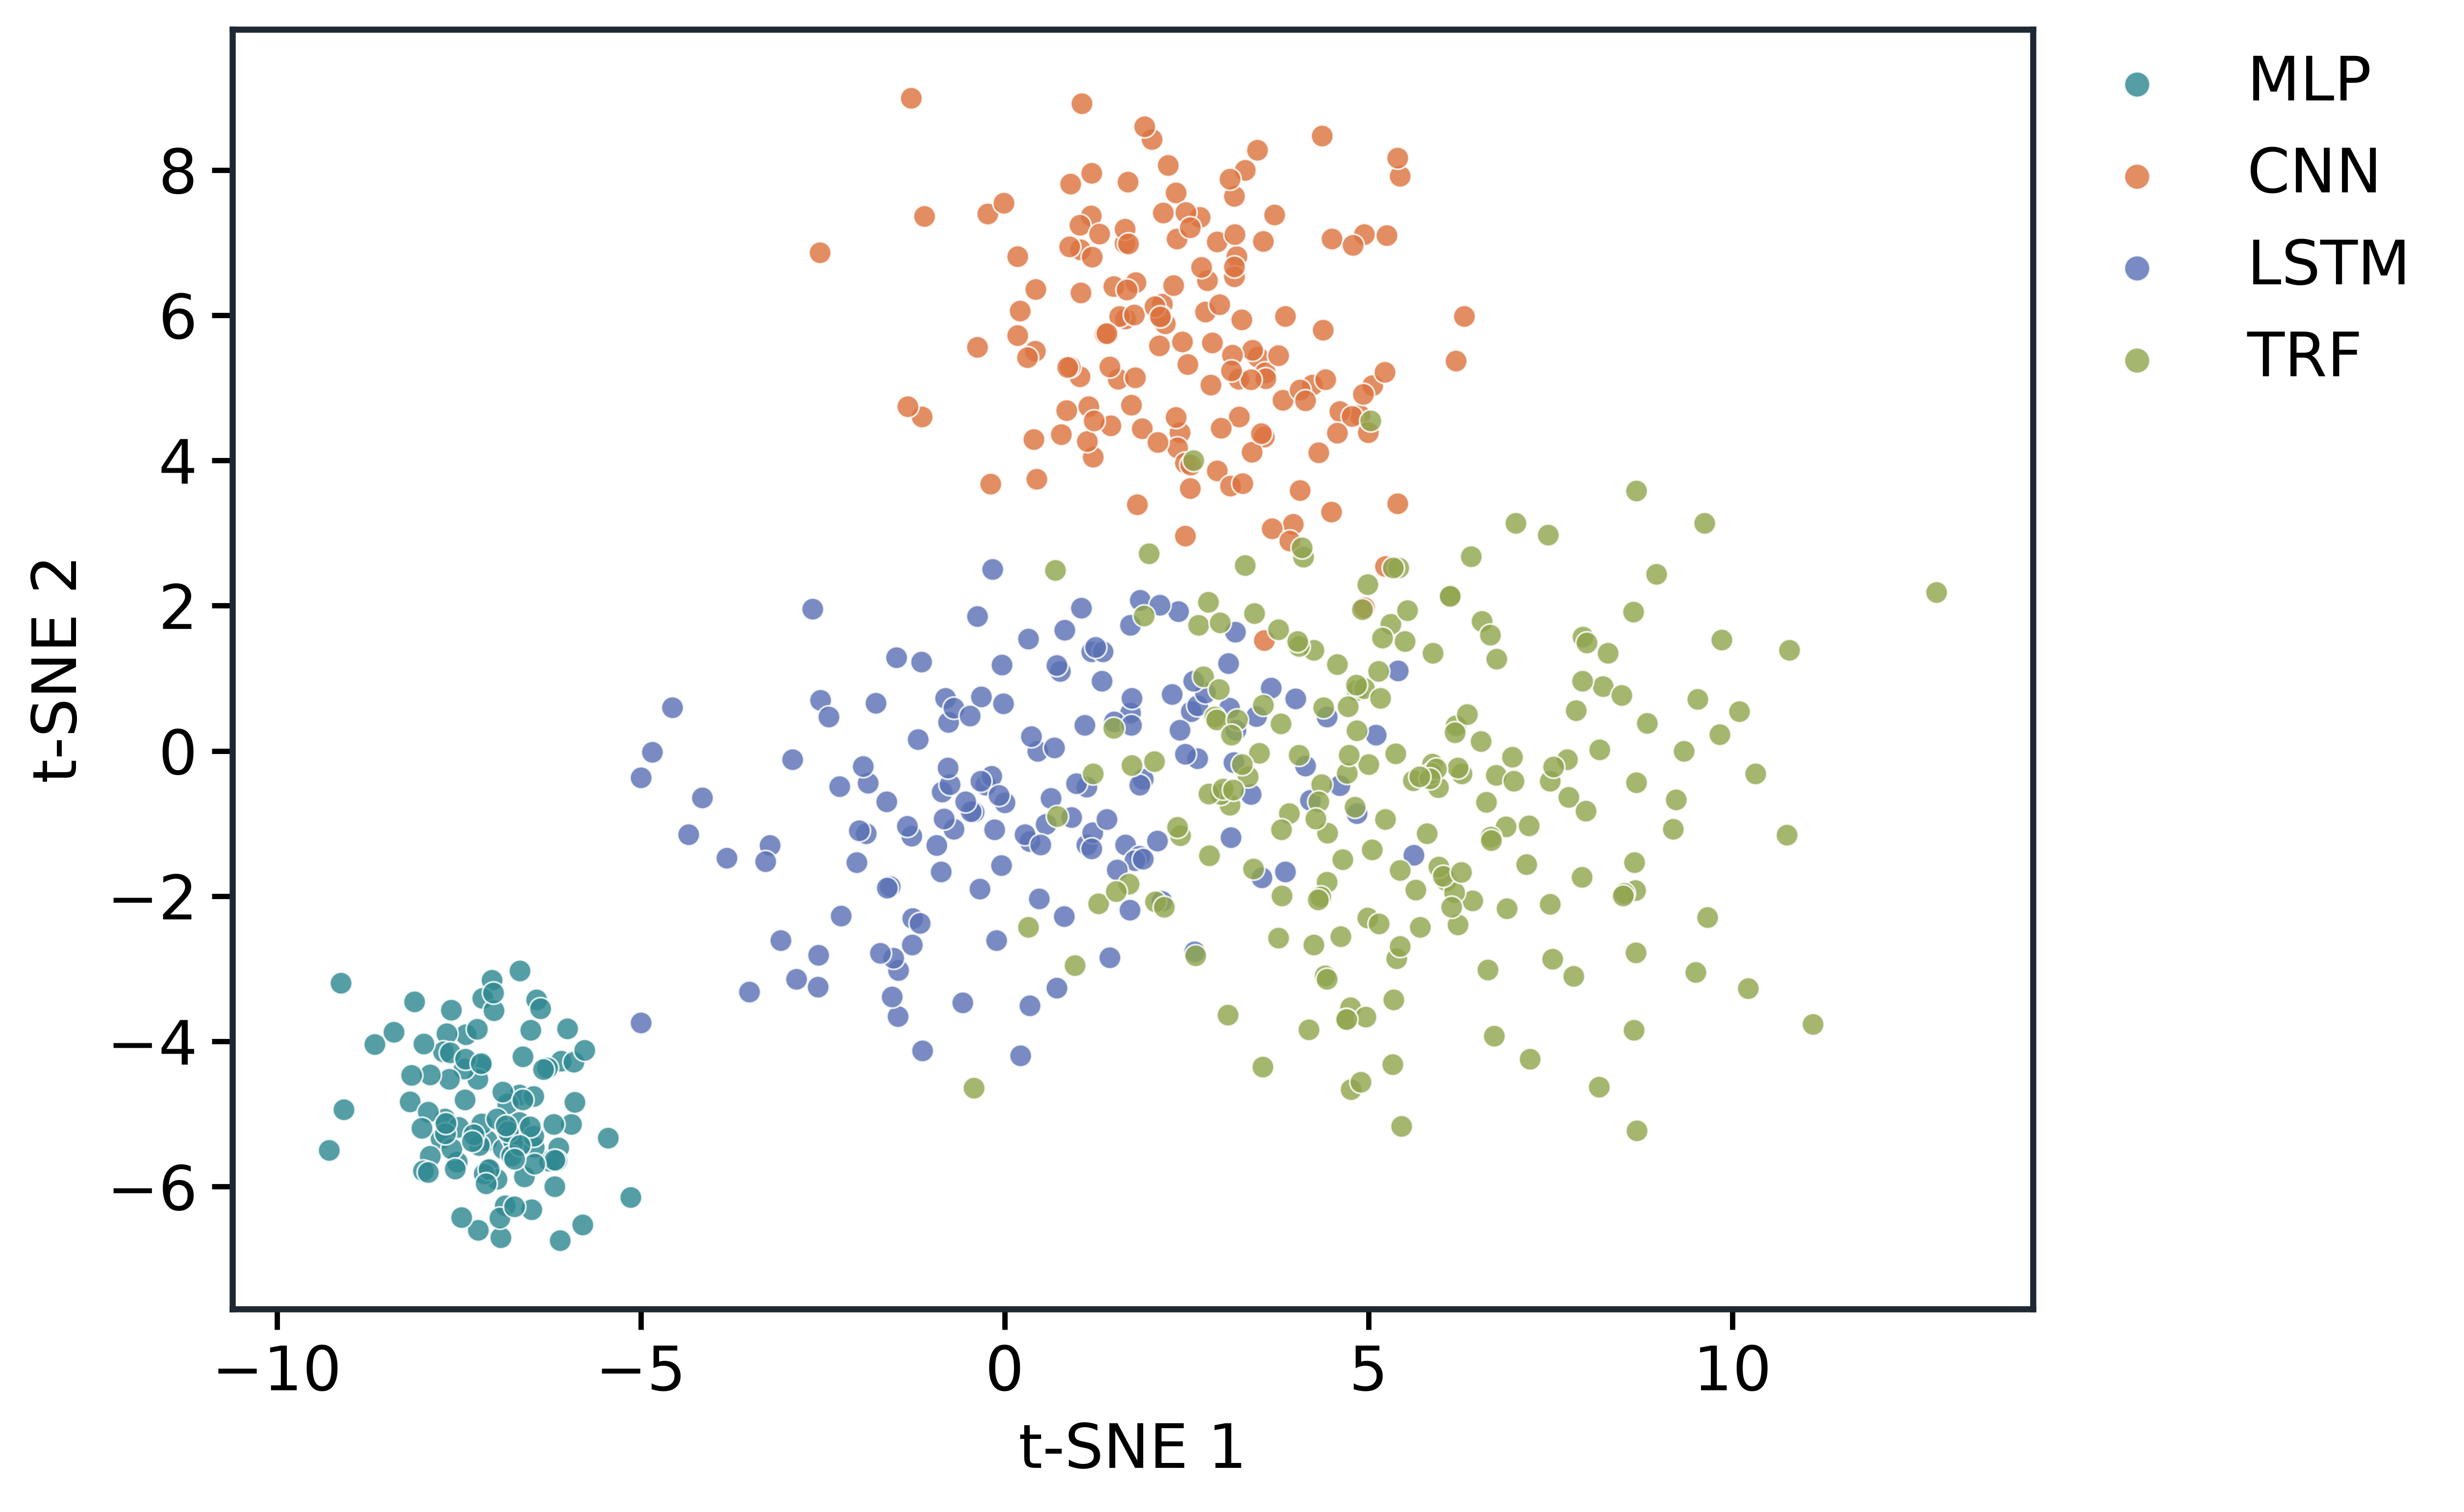

In [3]:
from IPython.display import Image, display

# Set these values for each workbook. Leave a value as None to be prompted.
filename = 'tsne_demo_data.xlsx'
label_column = 'Architecture_Code'
x_column = 't-SNE_1'
y_column = 't-SNE_2'
x_label = 't-SNE 1'  # e.g. 'UMAP 1'; None prompts you
y_label = 't-SNE 2'  # e.g. 'UMAP 2'; None prompts you

# None creates <Excel name>_tsne_scatter.png beside the workbook.
output_path = None

status = main(filename, output_path, label_column, x_column, y_column, x_label, y_label)
if status == 0:
    png_path = Path(output_path) if output_path else Path(filename).with_name(f"{Path(filename).stem}_tsne_scatter.png")
    display(Image(filename=str(png_path), width=700))

## Expected Excel structure

The first worksheet should have one header row and one point per data row. Extra columns are allowed. For example:

| Sample_ID | Architecture | t-SNE_1 | t-SNE_2 |
|---|---|---:|---:|
| MLP-001 | MLP | -6.25 | -5.64 |
| CNN-001 | CNN | 2.10 | 1.85 |

The output is saved as `<Excel name>_tsne_scatter.png` unless `output_path` is set explicitly.